In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## EDA

In [2]:
df = pd.read_csv('data/student-por.csv', sep=';')



df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [3]:

df.dtypes




school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object

In [4]:
df.columns = df.columns.str.lower()

categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')


df.head()


,school,sex,age,address,famsize,pstatus,medu,fedu,mjob,fjob,...,famrel,freetime,goout,dalc,walc,health,absences,g1,g2,g3
0,gp,f,18,u,gt3,a,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,gp,f,17,u,gt3,t,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,gp,f,15,u,le3,t,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,gp,f,15,u,gt3,t,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,gp,f,16,u,gt3,t,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [5]:
df.shape

(649, 33)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   pstatus     649 non-null    str  
 6   medu        649 non-null    int64
 7   fedu        649 non-null    int64
 8   mjob        649 non-null    str  
 9   fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [7]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
pstatus       0
medu          0
fedu          0
mjob          0
fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
dalc          0
walc          0
health        0
absences      0
g1            0
g2            0
g3            0
dtype: int64

In [8]:
df.describe().round(2)

,age,medu,fedu,traveltime,studytime,failures,famrel,freetime,goout,dalc,walc,health,absences,g1,g2,g3
count,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00
mean,16.74,2.51,2.31,1.57,1.93,0.22,3.93,3.18,3.18,1.50,2.28,3.54,3.66,11.40,11.57,11.91
std,1.22,1.13,1.10,0.75,0.83,0.59,0.96,1.05,1.18,0.92,1.28,1.45,4.64,2.75,2.91,3.23
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00
25%,16.00,2.00,1.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,2.00,0.00,10.00,10.00,10.00
50%,17.00,2.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,2.00,11.00,11.00,12.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,6.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,32.00,19.00,19.00,19.00


<Axes: xlabel='g3', ylabel='Count'>

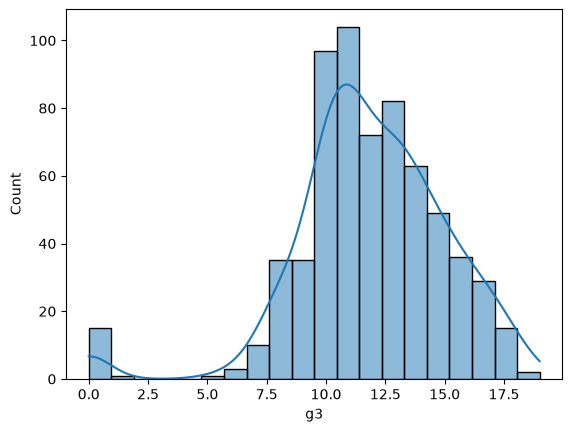

In [9]:
sns.histplot(df.g3, bins=20, kde=True)

<Axes: xlabel='g2', ylabel='Count'>

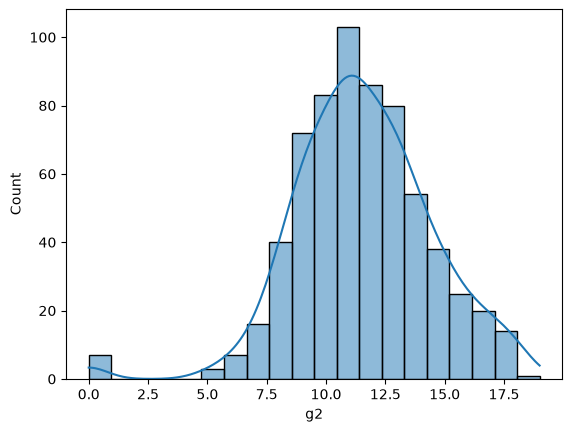

In [10]:
sns.histplot(df.g2, bins=20, kde=True)

In [11]:
(df.g3 == 0).sum(), (df.g3 == 0).mean()


(np.int64(15), np.float64(0.023112480739599383))

In [12]:
df[df.g3 == 0][['g1','g2','absences','failures']].describe()


,g1,g2,absences,failures
count,15.000000,15.000000,15.0,15.000000
mean,7.066667,3.800000,0.0,0.800000
std,1.791514,3.783422,0.0,0.861892
min,4.000000,0.000000,0.0,0.000000
25%,6.000000,0.000000,0.0,0.000000
50%,7.000000,5.000000,0.0,1.000000
75%,8.000000,7.000000,0.0,1.000000
max,11.000000,9.000000,0.0,3.000000


In [13]:
df[df.g3 == 0][['g1','g2','g3']].head(20)

,g1,g2,g3
163,11,9,0
440,7,0,0
519,8,7,0
563,7,0,0
567,4,0,0
583,8,6,0
586,8,8,0
597,9,0,0
603,5,0,0
605,5,0,0


**Decision 1: Remove students with G3 = 0 (15 students, 2.3%)**

None of these students has G1 = 0. Their first-period grades range from 4 to 11, but they still end up with a final grade of 0. In 7 of the 15 cases G2 is also 0, so a zero in G2 is usually followed by a zero in G3. The histogram of G3 also shows a separate spike at 0, apart from the otherwise roughly normal distribution.

This suggests that these students dropped out or missed the final exam. It does not look like a real grade. They are therefore removed, and the model predicts the final grade for students who complete the course.


In [14]:

df = df[df.g3 > 0].reset_index(drop=True)
(df.g3 == 0).sum(), (df.g3 == 0).mean()

(np.int64(0), np.float64(0.0))

In [15]:
numerical = ['age', 'medu', 'fedu', 'traveltime', 'studytime', 'failures',
             'famrel', 'freetime', 'goout', 'dalc', 'walc', 'health', 'absences']
categorical = [c for c in df.columns if c not in numerical + ['g1', 'g2', 'g3']]

In [16]:
df[numerical].corrwith(df.g3).sort_values()


failures     -0.387703
dalc         -0.211002
absences     -0.196031
walc         -0.184987
traveltime   -0.122875
goout        -0.119732
freetime     -0.114972
health       -0.101731
age          -0.038011
famrel        0.071413
fedu          0.197471
studytime     0.245955
medu          0.272032
dtype: float64

In [17]:
df[['g1', 'g2']].corrwith(df.g3)

g1    0.866208
g2    0.933780
dtype: float64

### G1 and G2

G1 and G2 correlate strongly with G3 (0.87 and 0.93) but are excluded. The model is meant to predict the final grade at the start of the school year, before any period grades exist.

In [18]:
df = df.drop(columns=['g1', 'g2'])


In [19]:
global_mean = df.g3.mean()

from IPython.display import display

for c in categorical:
    print(c)
    df_group = df.groupby(c).g3.agg(['mean', 'count'])
    df_group['diff'] = (df_group['mean']-global_mean).round(3)
    df_group['risk'] = (df_group['mean']/global_mean).round(3)
    display(df_group)
    print()

school


,mean,count,diff,risk
school,,,,
gp,12.606635,422,0.419,1.034
ms,11.353774,212,-0.834,0.932



sex


,mean,count,diff,risk
sex,,,,
f,12.481383,376,0.294,1.024
m,11.759690,258,-0.428,0.965



address


,mean,count,diff,risk
address,,,,
r,11.679144,187,-0.509,0.958
u,12.400447,447,0.213,1.017


... (24 outputs left out)


internet


,mean,count,diff,risk
internet,,,,
no,11.562500,144,-0.625,0.949
yes,12.371429,490,0.184,1.015



romantic


,mean,count,diff,risk
romantic,,,,
no,12.309406,404,0.122,1.010
yes,11.973913,230,-0.214,0.982


### EDA summary

- G3 ranges from 1 to 19 (mean ≈ 12) after removing 15 likely dropouts. No long tail, so no log transform.
- Strongest numerical features: failures (-0.39), medu (0.27), studytime (0.25), dalc (-0.21), absences (-0.20).
- Strongest categorical features: higher (no: -2.7 vs. mean), school (MS: -0.8), parent is a teacher (+1.3 to +1.8).
- Little to no effect: famsize, pstatus, famsup.
- All relationships are weak to moderate, so a relatively high error is expected without G1 and G2.

## Validation framework

In [20]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_full_train = df_full_train.g3.values
y_train = df_train.g3.values
y_val = df_val.g3.values
y_test = df_test.g3.values

del df_full_train['g3']
del df_train['g3']
del df_val['g3']
del df_test['g3']

len(df_train), len(df_val), len(df_test)

(380, 127, 127)

In [21]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

dicts_train = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(dicts_train)

dicts_val = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(dicts_val)

X_train.shape, X_val.shape


((380, 56), (127, 56))

## Linear model

In [22]:
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error

y_pred_baseline = np.full(len(y_val), y_train.mean())
rmse_baseline = root_mean_squared_error(y_val, y_pred_baseline)

print(f'Baseline RMSE: {rmse_baseline:.3f}')

Baseline RMSE: 2.378


In [23]:
model = Ridge(alpha=1.0, random_state=1)
model.fit(X_train, y_train)

y_pred = model.predict(X_val)
rmse_ridge = root_mean_squared_error(y_val, y_pred)

print(f'Ridge RMSE: {rmse_ridge:.3f}')

Ridge RMSE: 1.990


In [24]:
results = {
    'baseline': rmse_baseline,
    'ridge': rmse_ridge,
}

In [25]:
scores = []

for alpha in [0, 0.01, 0.1, 1, 10, 100, 1000]:
    model = Ridge(alpha=alpha, random_state=1)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred)
    scores.append((alpha, rmse))

df_scores = pd.DataFrame(scores, columns=['alpha', 'rmse'])
df_scores

,alpha,rmse
0,0.00,2.170994
1,0.01,1.996626
2,0.10,1.995993
3,1.00,1.990130
4,10.00,1.958574
5,100.00,1.974404
6,1000.00,2.145623


In [26]:
results['ridge'] = df_scores.rmse.min()

In [27]:
print(results )

{'baseline': 2.378458435594215, 'ridge': np.float64(1.9585738915092294)}


### Ridge regression

- Ridge (RMSE 1.959 with alpha = 10) clearly beats the baseline (2.378).
- Without regularization (alpha = 0) the RMSE is 2.17, since the one-hot columns are linearly dependent.
- Very strong regularization (alpha = 1000) pushes the model towards the baseline.
- The RMSE varies little for alpha between 0.01 and 100.

## Decision tree


In [28]:
from sklearn.tree import DecisionTreeRegressor

scores = []

for depth in [1, 2, 3, 4, 5, 6, 10, 15, 20, None]:
    dt = DecisionTreeRegressor(max_depth=depth, random_state=1)
    dt.fit(X_train, y_train)

    y_pred = dt.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred)
    scores.append((depth, rmse))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'rmse'])
df_scores


,max_depth,rmse
0,1.0,2.160089
1,2.0,2.111754
2,3.0,2.136518
3,4.0,2.207146
4,5.0,2.294875
5,6.0,2.422900
6,10.0,2.806715
7,15.0,2.967010
8,20.0,3.001312
9,NaN,3.001312


<Axes: xlabel='max_depth', ylabel='min_samples_leaf'>

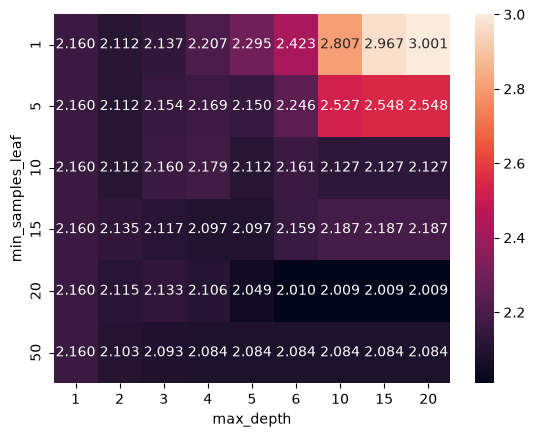

In [29]:
scores = []

for depth in [1, 2, 3, 4, 5, 6, 10, 15, 20]:
    for s in [1, 5, 10, 15, 20, 50]:
        dt = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=s, random_state=1)
        dt.fit(X_train, y_train)

        y_pred = dt.predict(X_val)
        rmse = root_mean_squared_error(y_val, y_pred)
        scores.append((depth, s, rmse))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'rmse'])

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='rmse')
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

In [30]:
results['decision_tree'] = 2.010

### Decision tree

- Best: max_depth = 6, min_samples_leaf = 20 (RMSE 2.010). Deeper trees give the same result, so the simpler one is chosen.
- Deep trees with small leaves overfit (RMSE up to 3.0, worse than the baseline).
- min_samples_leaf matters more than max_depth on this small dataset.
- A single tree is worse than Ridge (1.959).


## Random forest

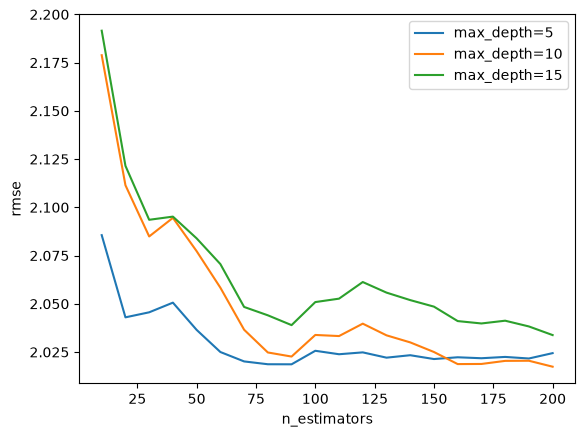

In [31]:
from sklearn.ensemble import RandomForestRegressor

scores = []

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestRegressor(n_estimators=n, max_depth=d,
                                   random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict(X_val)
        rmse = root_mean_squared_error(y_val, y_pred)
        scores.append((d, n, rmse))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'n_estimators', 'rmse'])

for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.rmse, label=f'max_depth={d}')

plt.xlabel('n_estimators')
plt.ylabel('rmse')
plt.legend()

<Axes: xlabel='max_depth', ylabel='min_samples_leaf'>

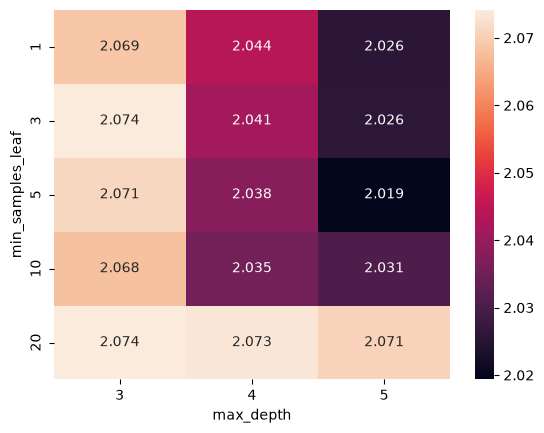

In [32]:
scores = []

for d in [3, 4, 5]:
    for s in [1, 3, 5, 10, 20]:
        rf = RandomForestRegressor(n_estimators=100, max_depth=d,
                                   min_samples_leaf=s,
                                   random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict(X_val)
        rmse = root_mean_squared_error(y_val, y_pred)
        scores.append((d, s, rmse))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'rmse'])

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='rmse')
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

In [33]:
results['random_forest'] = 2.019

### Random forest

- RMSE levels off at about 70 to 80 trees. More trees only add noise and training time.
- Shallow trees (max_depth = 5) work best, deeper trees overfit.
- Best: max_depth = 5, min_samples_leaf = 5, n_estimators = 100 (RMSE 2.019).


## XGBoost

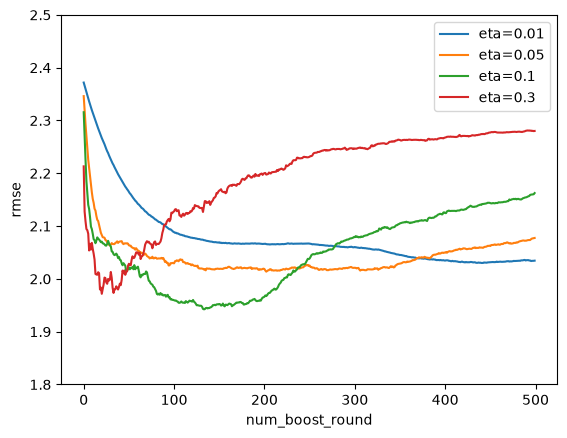

In [34]:
import xgboost as xgb

features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

watchlist = [(dtrain, 'train'), (dval, 'val')]

scores = {}

for eta in [0.01, 0.05, 0.1, 0.3]:
    xgb_params = {
        'eta': eta,
        'max_depth': 3,
        'min_child_weight': 1,

        'objective': 'reg:squarederror',
        'eval_metric': 'rmse',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }

    evals_result = {}
    model = xgb.train(xgb_params, dtrain, num_boost_round=500,
                      evals=watchlist, evals_result=evals_result,
                      verbose_eval=False)

    scores[eta] = evals_result['val']['rmse']

for eta, rmse in scores.items():
    plt.plot(rmse, label=f'eta={eta}')

plt.ylim(1.8, 2.5)
plt.xlabel('num_boost_round')
plt.ylabel('rmse')
plt.legend()

In [35]:
for eta, rmse in scores.items():
    best_round = int(np.argmin(rmse))
    print(f'eta={eta}: best rmse {min(rmse):.3f} at round {best_round}')

eta=0.01: best rmse 2.030 at round 440
eta=0.05: best rmse 2.014 at round 202
eta=0.1: best rmse 1.942 at round 133
eta=0.3: best rmse 1.972 at round 20


In [36]:
scores = {}

for depth in [2, 3, 4, 6]:
    for mcw in [1, 5, 10]:
        xgb_params = {
            'eta': 0.1,
            'max_depth': depth,
            'min_child_weight': mcw,

            'objective': 'reg:squarederror',
            'eval_metric': 'rmse',
            'nthread': 8,
            'seed': 1,
            'verbosity': 1,
        }

        evals_result = {}
        model = xgb.train(xgb_params, dtrain, num_boost_round=300,
                          evals=watchlist, evals_result=evals_result,
                          verbose_eval=False)

        rmse = evals_result['val']['rmse']
        scores[(depth, mcw)] = (min(rmse), int(np.argmin(rmse)))

df_scores = pd.DataFrame(
    [(d, m, r, n) for (d, m), (r, n) in scores.items()],
    columns=['max_depth', 'min_child_weight', 'rmse', 'best_round']
)
df_scores.sort_values('rmse').head()

,max_depth,min_child_weight,rmse,best_round
0,2,1,1.920981,237
2,2,10,1.941065,216
3,3,1,1.942402,133
10,6,5,1.974358,18
1,2,5,1.980588,148


In [37]:
results['xgboost'] = df_scores.rmse.min()

df_scores.rmse.min()


np.float64(1.9209806040151518)

### XGBoost

- eta = 0.1 gives the best result. Higher eta overfits early, lower eta learns too slowly.
- Best: eta = 0.1, max_depth = 2, min_child_weight = 1, 237 rounds (RMSE 1.921).
- Shallow trees work best, as for the other tree models.

## Model selection

In [38]:
from sklearn.model_selection import KFold

def train_ridge(df_train, y_train, alpha=10):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = Ridge(alpha=alpha, random_state=1)
    model.fit(X_train, y_train)

    return dv, model


def predict_ridge(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)

    return model.predict(X)


def train_xgb(df_train, y_train, xgb_params, num_boost_round):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    features = list(dv.get_feature_names_out())
    dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)

    model = xgb.train(xgb_params, dtrain, num_boost_round=num_boost_round)

    return dv, model


def predict_xgb(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)

    features = list(dv.get_feature_names_out())
    dX = xgb.DMatrix(X, feature_names=features)

    return model.predict(dX)

In [39]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 2,
    'min_child_weight': 1,

    'objective': 'reg:squarederror',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}
num_boost_round = 237

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores_baseline = []
scores_ridge = []
scores_xgb = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    y_tr = y_full_train[train_idx]
    y_va = y_full_train[val_idx]

    y_pred = np.full(len(y_va), y_tr.mean())
    scores_baseline.append(root_mean_squared_error(y_va, y_pred))

    dv, model = train_ridge(df_tr, y_tr, alpha=10)
    y_pred = predict_ridge(df_va, dv, model)
    scores_ridge.append(root_mean_squared_error(y_va, y_pred))

    dv, model = train_xgb(df_tr, y_tr, xgb_params, num_boost_round)
    y_pred = predict_xgb(df_va, dv, model)
    scores_xgb.append(root_mean_squared_error(y_va, y_pred))

print(f'Baseline: {np.mean(scores_baseline):.3f} +- {np.std(scores_baseline):.3f}')
print(f'Ridge:    {np.mean(scores_ridge):.3f} +- {np.std(scores_ridge):.3f}')
print(f'XGBoost:  {np.mean(scores_xgb):.3f} +- {np.std(scores_xgb):.3f}')

Baseline: 2.718 +- 0.183
Ridge:    2.253 +- 0.187
XGBoost:  2.265 +- 0.164


### Model selection (5-fold cross-validation)

| Model | RMSE (mean ± std) |
|---|---|
| Baseline | 2.718 ± 0.183 |
| Ridge (alpha = 10) | 2.253 ± 0.187 |
| XGBoost (eta = 0.1, max_depth = 2, 237 rounds) | 2.265 ± 0.164 |

- The difference between Ridge and XGBoost (0.012) is much smaller than the variation between folds (≈ 0.18), so neither is clearly better.
- Ridge is chosen as the final model: it is simpler, faster and easier to interpret.
- The RMSE from cross-validation is higher than on the single validation split, which was optimistic due to its small size and because it was used for tuning.

## Final model

In [41]:
dv, model = train_ridge(df_full_train, y_full_train, alpha=10)

y_pred = predict_ridge(df_test, dv, model)
rmse_test = root_mean_squared_error(y_test, y_pred)

print(f'Test RMSE: {rmse_test:.3f}')

Test RMSE: 2.137


### Final model

Ridge (alpha = 10) trained on the full training set (train + validation).

Test RMSE: 2.137, consistent with the cross-validation estimate. On average, the predicted final grade is about 2 points off on the 0 to 20 scale.